# Customer Segmentation Using K-Means: Comparing Two-Feature and Three-Feature Models

## Data Source
The mall customer dataset is a hypothetical dataset containing various attributes about customers such as gender, age, and annual income.

## Dataset Attributes
* CustomerID: unique customer identification number  
* Gender: customer gender (Male or Female)  
* Age: customer age in years  
* Annual Income: annual customer income (thousands of dollars)  
* Spending Score: a score based on customer behaviour and spending habits





In [23]:
# Import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

%matplotlib inline

sns.set_theme(style="whitegrid")

In [2]:
# Load the customer dataset
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Load and explore data

In [3]:
# Rename the original Genre column 
df = df.rename(columns={"Genre": "Gender"})

#Inspect the dataset
print("Dataset shape: ", df.shape)

display(df.head())

print("\nDataset Information: ")
df.info()

print("\nMissing Values: ")
print(df.isnull().sum())

print("\nDuplicate Rows: ", df.duplicated().sum())

print("\nDescriptive Statistics: ")
display(df.describe())


Dataset shape:  (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values: 
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows:  0

Descriptive Statistics: 


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Preprocessing and Feature Selection

In [4]:
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Feature Selection** 

The objective of this analysis is to identify customer segments based on their annyal income and spending score. 

As K-Means is an unsupervised learning algorithm, there is no predefined target or outcome variable. Instead, the algorithm identifies groups of customers based on similarities in the selected features. 

Annual income and spending score were chosen because they provide two relevant dimensions for exploring customer purchasing behaviour and potential market segments. 


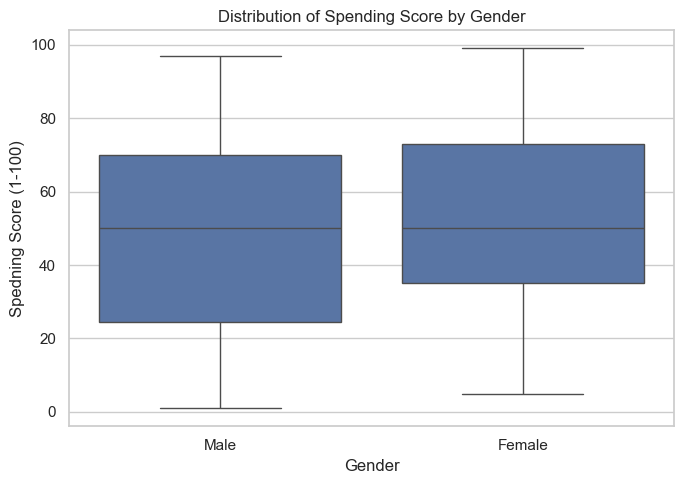

In [5]:
# Explore the binary independent feature (Gender)

plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="Gender",
    y="Spending Score (1-100)"
)

plt.title("Distribution of Spending Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Spedning Score (1-100)")

plt.tight_layout()
plt.show()


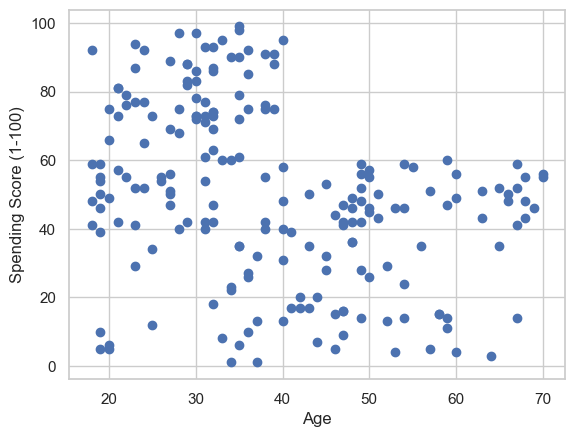

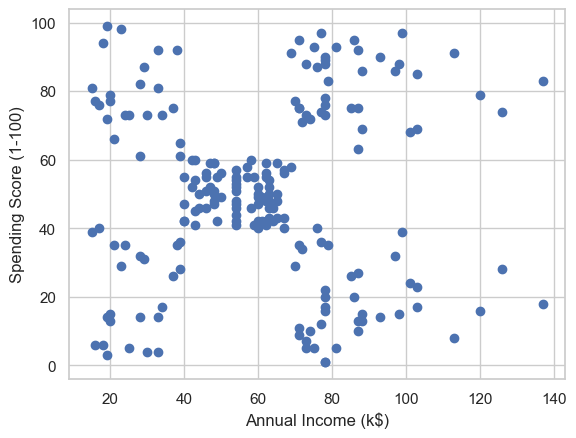

In [6]:
# Explore the continuous independent features (Age and Annual Income)

for f in df.columns[2:-1]:
  plt.scatter(df[f], df['Spending Score (1-100)'])
  plt.xlabel(f)
  plt.ylabel('Spending Score (1-100)')
  plt.show()

The scatterplot of annual income against spending score suggests that customers may form several distinct groups. 

However, the number of clusters cannot be determined reliably through visual inspection alone. 

To investigate an appropriate number of clusters, the elbow method and silhouette scores will be used to compare different values of K.

## K-Means Clustering

### Selecting K

In [7]:
# Prepare data for clustering, note that we do not supply y in an unsupervised learning task.
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].to_numpy()

print("Clustering data shape: ", X.shape)


Clustering data shape:  (200, 2)



It is clear from the distribution of the data choosing 5 clusters is a likely option for our choice of K.

However, for illustration purposes, we will also show you the so-called elbow method for choosing a value for K. The elbow method is commonly used strategy in which the algorithm is run multiple times with increasing values of K. This is then plotted against the sum of squared distances of samples to their closest cluster center (called inertia). The value of K to choose is identified from the resulting plot where there is an 'elbow' in the graph. 

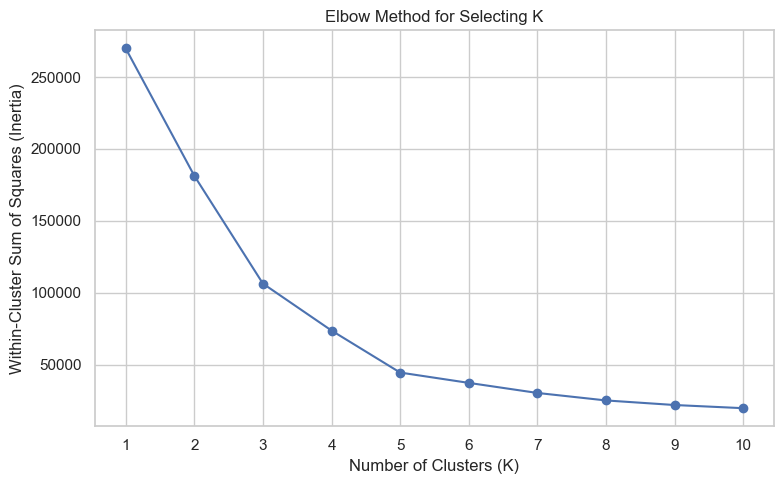

In [8]:
# Evaluate inertia for different numbers of clusters

k_values = range(1, 11)
inertias = []

for k in k_values:
    model=KMeans(
        n_clusters=k, 
        init="k-means++",
        random_state=0,
        n_init=10
    )

    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8,5))

plt.plot(
    list(k_values), 
    inertias,
    marker="o"
)

plt.title("Elbow Method for Selecting K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(k_values))

plt.tight_layout()
plt.show()


The elbow runs from K=3 to K=5. In cases like this, it is not always clear which value within the elbow is the most optimal. In order to investigate this further we will carry out a Silhouette analysis.

### Fit a K-Means Model and Visualise the Outcome 

,K,Silhouette Score
0,2,0.297
1,3,0.468
2,4,0.493
3,5,0.554
4,6,0.538
5,7,0.526
6,8,0.455
7,9,0.455
8,10,0.448


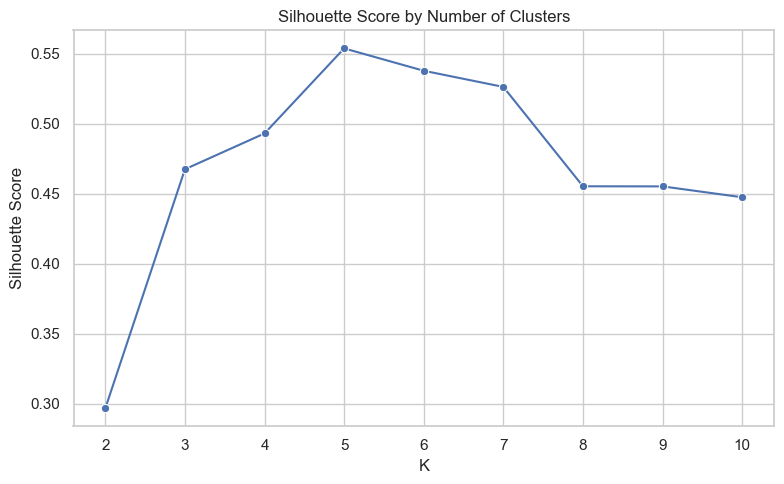

In [9]:
silhouette_results = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    silhouette_results.append({
        "K" : k,
        "Silhouette Score" : score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df.round(3))

plt.figure(figsize=(8, 5))

sns.lineplot(
    data = silhouette_df, 
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xticks(range(2,11))

plt.tight_layout()
plt.show()


The silhouette score increases considerably between K=4 and K=5, but not between K=5 and K=6.

## Final Customer Segmentation Model 

In [10]:
# Fit the final five-cluster model 

kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    random_state=0,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

print("Final Silhouette Score:")
print(round(silhouette_score(X, df["Cluster"]), 3))

display(df.head())


Final Silhouette Score:
0.554


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,3
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,3


### Cluster Model

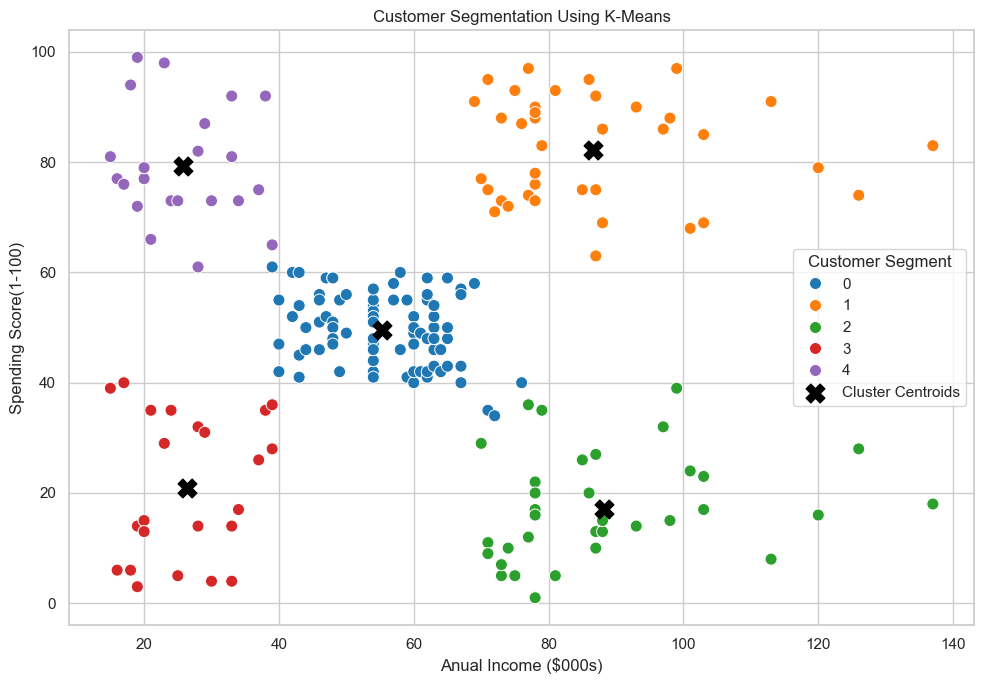

In [11]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df, 
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=75
)

centers = kmeans.cluster_centers_

plt.scatter(
    centers[:,0],
    centers[:,1],
    c="black",
    marker="X",
    s=180,
    label="Cluster Centroids"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Anual Income ($000s)")
plt.ylabel("Spending Score(1-100)")
plt.legend(title="Customer Segment")

plt.tight_layout()
plt.show()


## Customer Segment Analysis

In [22]:
cluster_summary = (
    df.groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Average_Age=("Age","mean"),
        Average_Income=("Annual Income (k$)", "mean"),
        Average_Spending_Score=("Spending Score (1-100)", "mean")
    )
    .round(2)
)

cluster_summary["Percentage_of_Customers"] = (
    cluster_summary["Customer_Count"]
    / len(df) * 100
).round(1)

display(cluster_summary)

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score,Percentage_of_Customers
Cluster,,,,,
0,81,42.72,55.30,49.52,40.5
1,39,32.69,86.54,82.13,19.5
2,35,41.11,88.20,17.11,17.5
3,23,45.22,26.30,20.91,11.5
4,22,25.27,25.73,79.36,11.0


## Business Insights and Recommendations

**Which customer groups represent potential opportunities?**

High-income customers with low spending scores may warrant further investigation into engagement, product relevance or purchasing preferences. Understand what they are buying and tailor any sales or products via their suggested marketing preferences.


**How might a retailer use these segments?**

A retailer couled test different marketing messges, loyalty offers or product recommendations for different customer groups. These should be presented as proposed experiments, not proven strategies.

**What additional information would improve the analysis?**

Transaction history, purchase frequency, product categories, campaign responses and actual customer spending would help validate whether these segments are commercially useful. 


## Limitations and Future Improvements

### Limitations

Althugh K-Means clustering identified distinct customer segments, there are several limitations that should be considered. 

Firstly, the model only considers Annual Income and Spending Score. WHile these varoabes help identify different customer segments, they do not account for other characteristics, such as age, purchase frequency, product preference or shopping habits, which may influence customer behaviour. 

Secondly, K-Means uses Euclidean distance to group customers based on their similarities. This method generally works best when clusters are relatively compact and well-separated. However, real customer behaviour may follow more complex patterns that cannot be fully captured by distance-based clustering. 

Finally, the dataaset contains only 200 customers, and Spending Score is an index rather than a direct measurement of actual expenditure. Therefore, the identified clusters should be considered as an exploratory test rather than definitive representations of customers purchasing behaviour. 

### Future Improvements 

To improve analysis, additional customer features could be introduced to investigate whether they reveal more meaningful segments. 

One potential improvement would be to include Age as a third feature and apply feature scaling to ensure that variables with different numerical ranges contribute more comparably to the clustering process. 

The elbow method and silhouette analysis could them be repeated to determine the most appropriate number of clusters for the expanded dataset. 

Comparing the resulting clsuters with the original two-feature model would help evaluate whether including additional customer information provides further insights into customer characteristics. 

Future research could also incorporate transaction history, purchase frequency and product preferences, alongside alternative clustering methods, to assess the robustness and business relevance of the customer segments. 



# Model 2 - Three-feature KMeans

The following section investigates the potential improvement by introducing Age as a third feature and comparing the resulting customer segments.

In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,3
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,3


#### Selecting K

In [24]:
three_features = [
    "Age", 
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

x = df[three_features]

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

print("Clustering Data Shape: ", x.shape)


Clustering Data Shape:  (200, 3)


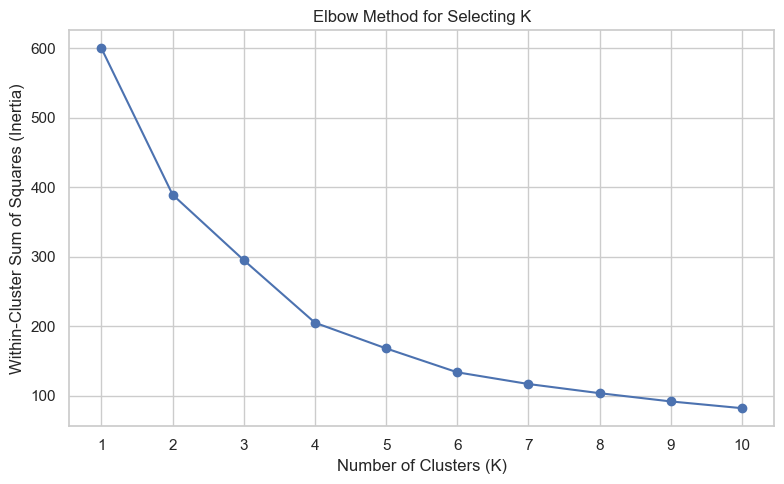

In [16]:
# Evaluate inertia for different numbers of clusters

k_values = range(1, 11)
inertias = []

for k in k_values:
    model=KMeans(
        n_clusters=k, 
        init="k-means++",
        random_state=0,
        n_init=10
    )

    model.fit(x_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8,5))

plt.plot(
    list(k_values), 
    inertias,
    marker="o"
)

plt.title("Elbow Method for Selecting K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(k_values))

plt.tight_layout()
plt.show()


### Silhouette Score of Three-features: Age, Annual Income (k$) and Spending Score (1-100)

,K,Silhouette Score
0,2,0.335
1,3,0.358
2,4,0.404
3,5,0.417
4,6,0.427
5,7,0.417
6,8,0.409
7,9,0.421
8,10,0.409


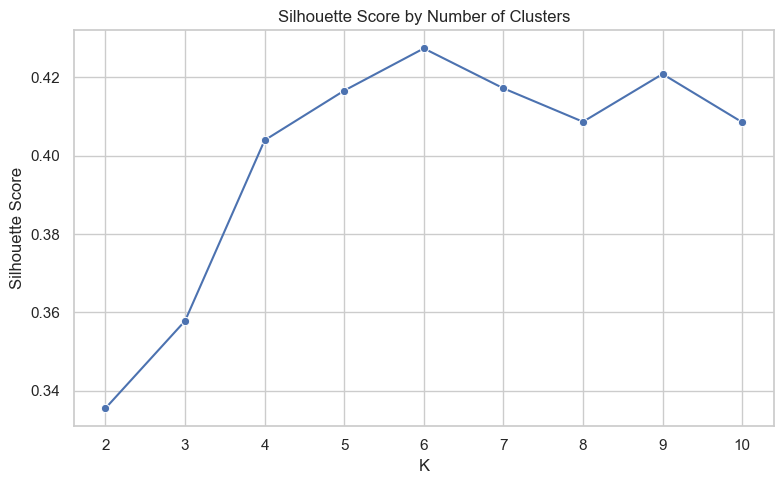

In [17]:
silhouette_results = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    labels = model.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)

    silhouette_results.append({
        "K" : k,
        "Silhouette Score" : score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df.round(3))

plt.figure(figsize=(8, 5))

sns.lineplot(
    data = silhouette_df, 
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xticks(range(2,11))

plt.tight_layout()
plt.show()


In [18]:
kmeans_three_features = KMeans (
    n_clusters = 6,
    init = "k-means++",
    random_state=0,
    n_init=10
)

df['Clusters_three'] = kmeans_three_features.fit_predict(x_scaled)

print("Final Silhouette Score: ")
print(round(silhouette_score(x_scaled, df['Clusters_three']), 3))

display(df.head())


Final Silhouette Score: 
0.427


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Clusters_three
0,1,Male,19,15,39,3,5
1,2,Male,21,15,81,4,5
2,3,Female,20,16,6,3,4
3,4,Female,23,16,77,4,5
4,5,Female,31,17,40,3,4


### Customer Cluster

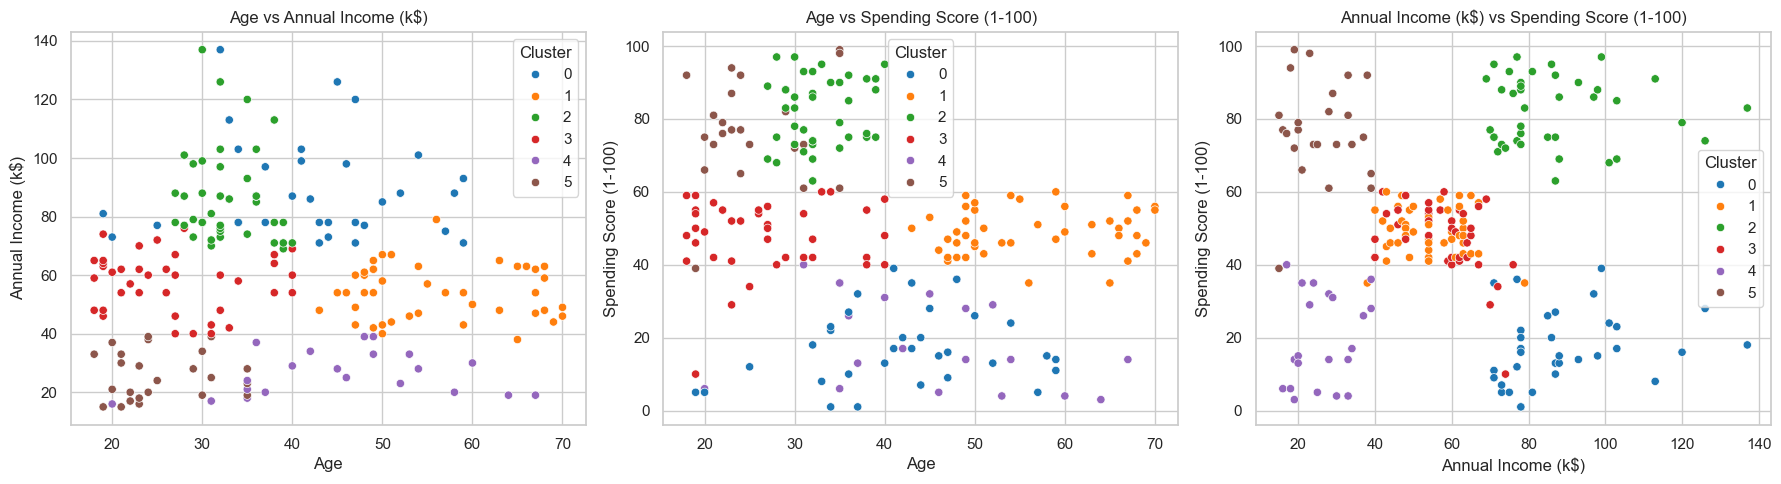

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

feature_pairs = [
    ("Age", "Annual Income (k$)"),
    ("Age", "Spending Score (1-100)"),
    ("Annual Income (k$)", "Spending Score (1-100)")
]

for ax, (x_feature, y_feature) in zip(axes, feature_pairs):
    sns.scatterplot(
        data=df,
        x=x_feature,
        y=y_feature,
        hue="Clusters_three",
        palette="tab10",
        ax=ax
    )

    ax.set_title(f"{x_feature} vs {y_feature}")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.show()


In [20]:
# Summarise the size clusters

cluster_summary_three_feature = (
    df.groupby("Clusters_three")
    .agg(
        Customer_Count = ("CustomerID", "count"),
        Average_Age = ("Age", "mean"),
        Average_Income = ("Annual Income (k$)", "mean"),
        Average_Spending_Score = ("Spending Score (1-100)", "mean")
    )
    .round(2)
)

display(cluster_summary_three_feature)



,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Clusters_three,,,,
0,33,41.94,88.94,16.97
1,45,56.33,54.27,49.07
2,39,32.69,86.54,82.13
3,38,26.68,57.58,47.79
4,21,45.52,26.29,19.38
5,24,25.25,25.83,76.92


| clusters | Suggested Cluster Name | No. Customers | Avg. Age | Avg. Income | Avg. Spending Score |
| :-------: | :-----: | :------: | :------: | :-----: | :-------: |
| 0 | High-income, Low-spending | 33 | 41.94 | $88.94k | 16.97 |
| 1 | Older, Moderate-spending | 45 | 56.33 | $54.27k | 49.07 |
| 2 | High-income, High-spending | 39 | 32.69 | $86.54k | 82.13 |
| 3 | Younger, Moderate-spending | 38 | 26.68 | $57.58k | 47.79 |
| 4 | Low-income, Low-spending | 21 | 45.52 | $26.29k | 19.38 |
| 5 | Younger, Low-income, High-spending | 24 | 25.25 | $25.83k | 76.92 |


### Three-feature KMeans Model Interpretation

The K-Means model identified six customer segments based on Age, Annual Income and Spending Score, achieving a Silhouette score of 0.427.

The cluster profile reveal distinct customer characteristics; including high-income customers with either a high or low spending scores, lower-income customers with differing spending habits, and two moderate-spending groups that are only differentiated by age. 

The most interesting finding is the difference between cluster 1 (Older, Moderate-spending) and cluster 3 (Younger, Moderate-spending). Both have similar average incomes ($54.27K and $57.58k) and spending scores (49.07 and 47.79), but the only difference is their average age (56.33 and 26.68). A 30 year average age difference between the two sets of groups. This suggests that including Age can reveal additional distinctions between customers who otherwise appear similar based on income and spending score alone. What can be investigated further are the product categories these clusters purchase and see what product recommendations can be tailored to both of these groups. 

Although the three-feature model has a lower silhouette scre than the two-feature model, it provides additional demographic information that may be useful for developing and testing customer engagement strategies. 

However, these segments are exploratory. Further analysis using transaction histories, product preferences and campaign response data would be necessary to validate their commercial usefulness. 


### Business Insights 

| Cluster | Possible Business Actions | 
| :--: | :---: |
| 0 - High-income, Low-spending | Investigate why customers with relatively high incomes have low spending scores. Test whether more relevant product recommendations improve customer engagement. |
| 1 - Older, Moderate-Spending | Research product preferences and communication channels before testing tailored campaigns. | 
| 2 - High-income, High-spending | Explore a loyalty programme or premium product campaign for customers with high spending scores. | 
| 3 - Younger, Moderate-spending | Test targeted product discovery or engagement campaigns and compare results with Cluster 1 to see whether tailored campaigns help boost spending scores. |
| 4 - Low-income, Low-spending | Explore whether value-focussed offers are relevant to these customers. If offers such as sales or discounted products bring in more customers |
| 5 - Younger, Low-income, High-spending | Explore which products and experiences appeal to this group, while avoiding affordability assumptions. | 

## Comparison between both the Two-feature (Annual Income and Spending Score) and the Three-feature Model (Age, Annual Income and Spending Score)


## Comparing Two-Feature and Three-Feature Customer Segmentation

To investigate how including Age influeces customer segmentation, a cross-tabulation was performed to compare cluster assignments between the two models.

Clusters_three,0,1,2,3,4,5
Cluster,,,,,,
0,1,43,0,36,0,1
1,0,0,39,0,0,0
2,32,1,0,2,0,0
3,0,1,0,0,21,1
4,0,0,0,0,0,22


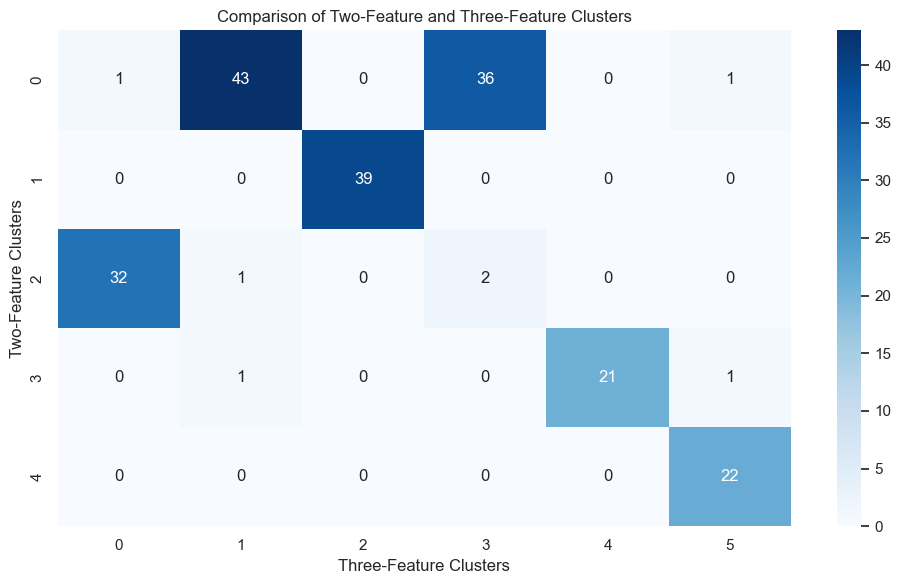

In [21]:
# Compare cluster assignments between both models

cluster_comparison = pd.crosstab(
    df["Cluster"],
    df["Clusters_three"]
)

display(cluster_comparison)

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_comparison,
    annot=True, 
    fmt="d",
    cmap="Blues"
)

plt.title("Comparison of Two-Feature and Three-Feature Clusters")
plt.xlabel("Three-Feature Clusters")
plt.ylabel("Two-Feature Clusters")

plt.tight_layout()
plt.show()


### Percentage of Cluster change from Two-feature model to Three-feature model

| Original Cluster | Main corresponding new cluster | Customers retained together |
| -- | -- | -- |
| 1 | Cluster 2 | 39 of 39 (100%) |
| 2 | Cluster 0 | 32 of 35 (91.4%) |
| 3 | Cluster 4 | 21 of 23 (91.3%) |
| 4 | Cluster 5 | 22 of 22 (100%) | 


## Cross-Tabulation: Comparing Cluster Assignments

A cross-tabulation was performed to investigate how customer assignments changed between the two-feature and three-feature K-Means models. 

The most significant change occurred in the original Two-feature Cluster 0, which contained 81 customers. Of these, 43 were assigned to Cluster 1 and 36 to Cluster 3 of the Three-feature Model, while the remaining two were assigned elsewhere. 

These newly formed groups had similar average annual incomes and spending scores but different age brackets, an average age of 56.33 and 26.68 years. This suggests that including Age helped distinguish customers who previously appeared similar based on income and spending characteristics. 

The other original clusters remained largely consistent. Two clusters retained all their customers within a single corresponding three-feature cluster, while two others retaimed more than 90%. 

Although the three-feature model produced a lower silhouette score (0.427 compared with 0.554), the cross-tabulation demonstrates how adding Age changes the segmentation and revelas potentially useful demographic distinctions. 


##### Conclusion 

The two-feature model provides a simpler segmentation based on income and spending behaviour, while the three-feature model offers additional age-based differentiation. The preferred model would depend on the business objective and should be validated using further customer and transaction data. 

The model experimented here is a foundation to how an unsupervised K-Means testing can be used to categorise customer data and help with informed-decision making. The model will be able to help with creating marketing strategies. 

